In [2]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2,
        ),
        "GB",
    )

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA L4
VRAM: 22.03 GB


## Clone the project and official ConsiStory

In [3]:
%cd /content

!rm -rf CMPE-261-Project
!rm -rf consistory

!git clone https://github.com/RishiJ12/CMPE-261-Project.git
!git clone https://github.com/NVlabs/consistory.git

/content
Cloning into 'CMPE-261-Project'...
remote: Enumerating objects: 43, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 43 (delta 12), reused 24 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (43/43), 27.54 MiB | 16.04 MiB/s, done.
Resolving deltas: 100% (12/12), done.
Cloning into 'consistory'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 18 (delta 1), reused 1 (delta 1), pack-reused 14 (from 1)
Receiving objects: 100% (18/18), 41.64 KiB | 20.82 MiB/s, done.
Resolving deltas: 100% (1/1), done.


#### switch to another branch if needed

In [4]:
%cd /content/CMPE-261-Project

# !git checkout feat/character-crop
# !git checkout refactor/add-storydiffusion-to-full-benchmark


!find src -maxdepth 1 -type f -print

/content/CMPE-261-Project
branch 'refactor/add-storydiffusion-to-full-benchmark' set up to track 'origin/refactor/add-storydiffusion-to-full-benchmark'.
Switched to a new branch 'refactor/add-storydiffusion-to-full-benchmark'
src/structure_metrics.py
src/controlnet_baseline.py
src/storydiffusion_csa.py
src/ip_adapter.py
src/character_reference.py
src/preprocessing.py
src/__init__.py
src/consistory.py


## test shared dependency environment

In [5]:
%pip uninstall -y \
    diffusers \
    transformers \
    huggingface_hub \
    accelerate \
    tokenizers \
    datasets \
    peft

Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1
Found existing installation: transformers 5.22.1
Uninstalling transformers-5.22.1:
  Successfully uninstalled transformers-5.22.1
Found existing installation: huggingface_hub 1.33.0
Uninstalling huggingface_hub-1.33.0:
  Successfully uninstalled huggingface_hub-1.33.0
Found existing installation: accelerate 1.15.0
Uninstalling accelerate-1.15.0:
  Successfully uninstalled accelerate-1.15.0
Found existing installation: tokenizers 0.23.3
Uninstalling tokenizers-0.23.3:
  Successfully uninstalled tokenizers-0.23.3
Found existing installation: datasets 4.8.5
Uninstalling datasets-4.8.5:
  Successfully uninstalled datasets-4.8.5
Found existing installation: peft 0.21.2
Uninstalling peft-0.21.2:
  Successfully uninstalled peft-0.21.2


In [6]:
%pip install -q --no-cache-dir \
    diffusers==0.25.1 \
    transformers==4.48.3 \
    tokenizers==0.21.0 \
    huggingface-hub==0.25.2 \
    accelerate==0.30.0 \
    safetensors \
    scikit-image==0.25.2 \
    scipy \
    scikit-learn \
    pandas \
    opencv-python-headless \
    matplotlib \
    pymupdf

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchtune 0.6.1 requires datasets, which is not installed.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.25.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.25.2 which is incompatible.


# **Restart session**

#### Do not rerun the install cell after restarting.

## Shared-environment setup

In [1]:
%cd /content/CMPE-261-Project

/content/CMPE-261-Project


In [2]:
import sys

sys.path.insert(
    0,
    "/content/CMPE-261-Project",
)

sys.path.insert(
    0,
    "/content/consistory",
)

In [3]:
import torch
import diffusers
import transformers
import accelerate
import huggingface_hub

print("torch:", torch.__version__)
print("diffusers:", diffusers.__version__)
print("transformers:", transformers.__version__)
print("accelerate:", accelerate.__version__)
print("huggingface_hub:", huggingface_hub.__version__)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

torch: 2.14.1+cu130
diffusers: 0.25.1
transformers: 4.48.3
accelerate: 0.30.0
huggingface_hub: 0.25.2


#### Test the two critical Diffusers features

In [4]:
from diffusers.models.embeddings import PositionNet

print("PositionNet available")

PositionNet available


In [5]:
from diffusers import (
    StableDiffusionControlNetPipeline,
)

print(
    "load_ip_adapter available:",
    hasattr(
        StableDiffusionControlNetPipeline,
        "load_ip_adapter",
    ),
)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/outputs.py:63: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(


load_ip_adapter available: True


/usr/local/lib/python3.13/dist-packages/diffusers/utils/outputs.py:63: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(


In [6]:
from consistory_run import (
    load_pipeline,
    run_anchor_generation,
    run_extra_generation,
)

print("Official ConsiStory imports succeeded")

Official ConsiStory imports succeeded


In [7]:
from src.preprocessing import (
    load_rgb,
    make_condition,
    show,
)

from src.controlnet_baseline import (
    load_controlnet_pipeline,
    run_sequence,
)

from src.ip_adapter import (
    attach_ip_adapter,
    run_sequence_ip_adapter,
)

from src.consistory import (
    install_torch_sdpa_fallback,
    load_consistory_pipeline,
    load_consistory_controlnet,
    make_control_image_processor,
    attach_controlnet,
    generate_anchor_caches,
    configure_dpm_solver_pp,
    run_sequence_consistory,
)

from src.structure_metrics import (
    to_edge_mask,
    compare_edge_masks,
    compare_structure,
)

print("Shared benchmark modules imported")

Shared benchmark modules imported


In [8]:
from pathlib import Path

REF_DIR = Path(
    "/content/drive/MyDrive/cmpe261_project/char_refs"
)

print("Character reference directory:")
print(REF_DIR)

if REF_DIR.exists():
    for path in REF_DIR.glob("*"):
        print(" -", path.name)
else:
    print("Reference directory not mounted/found yet.")

Character reference directory:
/content/drive/MyDrive/cmpe261_project/char_refs
Reference directory not mounted/found yet.


In [9]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [10]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cmpe261_project"
)

REF_DIR = PROJECT_ROOT / "char_refs"
PANEL_DIR = PROJECT_ROOT / "panels"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

print("Project root:", PROJECT_ROOT)
print("Project root exists:", PROJECT_ROOT.exists())

print("\nCharacter references:")
if REF_DIR.exists():
    for path in sorted(REF_DIR.glob("*")):
        print(" -", path.name)
else:
    print("char_refs folder not found")

print("\nPanels:")
if PANEL_DIR.exists():
    panel_files_found = sorted(PANEL_DIR.glob("*.png"))
    print("Found", len(panel_files_found), "panel images")
else:
    print("panels folder not found")

Project root: /content/drive/MyDrive/cmpe261_project
Project root exists: True

Character references:
 - vampire_ref.png

Panels:
Found 6 panel images


### Shared paths

In [11]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cmpe261_project"
)

PDF_PATH = (
    PROJECT_ROOT
    / "storyboard"
    / "Evicted-Storyboard.pdf"
)

STORYBOARD_DIR = (
    PROJECT_ROOT
    / "pages"
)

PANEL_DIR = (
    PROJECT_ROOT
    / "panels"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
)

REF_DIR = (
    PROJECT_ROOT
    / "char_refs"
)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PANEL_DIR:", PANEL_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("REF_DIR:", REF_DIR)

PROJECT_ROOT: /content/drive/MyDrive/cmpe261_project
PANEL_DIR: /content/drive/MyDrive/cmpe261_project/panels
OUTPUT_DIR: /content/drive/MyDrive/cmpe261_project/outputs
REF_DIR: /content/drive/MyDrive/cmpe261_project/char_refs


## Shared sequence

In [12]:
import glob

SEQ_NAME = "seq01"

panel_files = sorted(
    glob.glob(
        str(
            PANEL_DIR
            / f"{SEQ_NAME}_panel*.png"
        )
    )
)

CHARACTER = "a vampire"
SETTING = "blank background"

actions = [
    "jelly vaporizes as camera pans up",
    "vampire hands slowly come into screen, close-up",
    "hands rapidly push vaporized blood upwards, close-up",
    "camera pans upto vampire's face, close-up",
    "vampire inhales jelly mist from right hand, close-up",
    "vampire inhales jelly mist from left hand, close-up",
]

prompts = [
    f"{CHARACTER}, {action}, {SETTING}"
    for action in actions
]

prompts = prompts[:len(panel_files)]

print("Sequence:", SEQ_NAME)
print("Panels:", len(panel_files))
print("Prompts:", len(prompts))

for i, panel_file in enumerate(panel_files):
    print(
        f"{i + 1}: "
        f"{Path(panel_file).name}"
    )
    print(
        "   ",
        prompts[i],
    )

Sequence: seq01
Panels: 6
Prompts: 6
1: seq01_panel001.png
    a vampire, jelly vaporizes as camera pans up, blank background
2: seq01_panel002.png
    a vampire, vampire hands slowly come into screen, close-up, blank background
3: seq01_panel003.png
    a vampire, hands rapidly push vaporized blood upwards, close-up, blank background
4: seq01_panel004.png
    a vampire, camera pans upto vampire's face, close-up, blank background
5: seq01_panel005.png
    a vampire, vampire inhales jelly mist from right hand, close-up, blank background
6: seq01_panel006.png
    a vampire, vampire inhales jelly mist from left hand, close-up, blank background


## SD1.5 ControlNet config

In [13]:
SD15_CONFIG = {
    "base_model":
        "stable-diffusion-v1-5/stable-diffusion-v1-5",

    "controlnet":
        "lllyasviel/control_v11p_sd15_canny",

    "resolution": 512,

    "steps": 30,

    "guidance_scale": 7.5,

    "controlnet_conditioning_scale": 1.0,

    "seed": 42,

    "cond_mode": "canny",

    "canny_low": 100,

    "canny_high": 200,

    "prompt_suffix":
        "clean colored animation frame, "
        "consistent character design",

    "negative_prompt":
        "blurry, low quality, deformed, "
        "extra limbs, text, watermark",
}

## IP-Adapter config

In [14]:
IP_ADAPTER_CONFIG = {
    "repo":
        "h94/IP-Adapter",

    "subfolder":
        "models",

    "weight_name":
        "ip-adapter-plus_sd15.bin",

    "scale":
        0.2,
}

## ConsiStory config

In [15]:
CONSISTORY_CONFIG = {
    "base_model":
        "stabilityai/stable-diffusion-xl-base-1.0",

    "controlnet":
        "diffusers/controlnet-canny-sdxl-1.0",

    "resolution":
        1024,

    "steps":
        20,

    "guidance_scale":
        7.5,

    "controlnet_conditioning_scale":
        1.0,

    "seed":
        42,

    "cond_mode":
        "canny",

    "canny_low":
        100,

    "canny_high":
        200,

    "prompt_suffix":
        "clean colored animation frame, "
        "consistent character design",

    "negative_prompt":
        "blurry, low quality, deformed, "
        "extra limbs, text, watermark",

    "mask_dropout":
        0.5,

    "same_latent":
        False,

    "share_queries":
        True,

    "n_anchors":
        2,
}

### ConsiStory anchors

In [16]:
CONCEPT_TOKEN = [
    "vampire"
]

ANCHOR_PROMPTS = [
    (
        "a western animation vampire, "
        "front-facing portrait, "
        "clean character design"
    ),
    (
        "a western animation vampire, "
        "three-quarter view portrait, "
        "clean character design"
    ),
]

#### Verify inputs visually

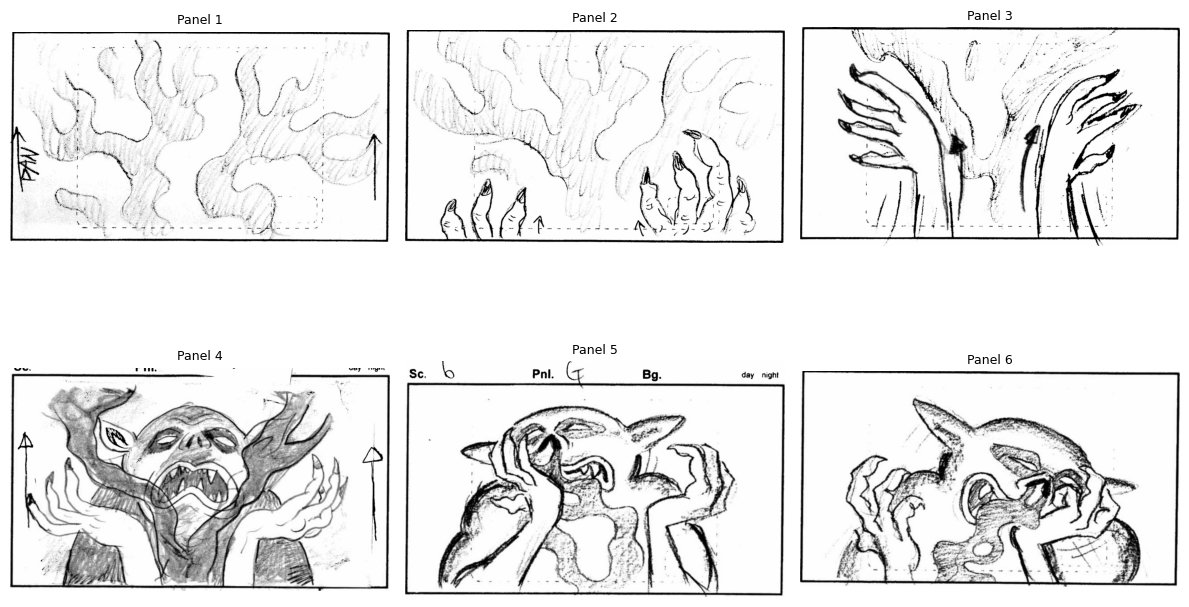

In [17]:
storyboards = [
    load_rgb(path)
    for path in panel_files
]

show(
    storyboards,
    titles=[
        f"Panel {i + 1}"
        for i in range(len(storyboards))
    ],
    cols=3,
    size=4,
)

## Load the ControlNet baseline

In [18]:
import torch

controlnet_pipe = load_controlnet_pipeline(
    cfg=SD15_CONFIG,
    device="cuda",
)

print("✓ SD1.5 ControlNet pipeline loaded")
print("Pipeline device:", controlnet_pipe.device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_token.py:90: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/996 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

... (11 outputs left out)

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

✓ SD1.5 ControlNet pipeline loaded
Pipeline device: cuda:0


✓ ControlNet test completed


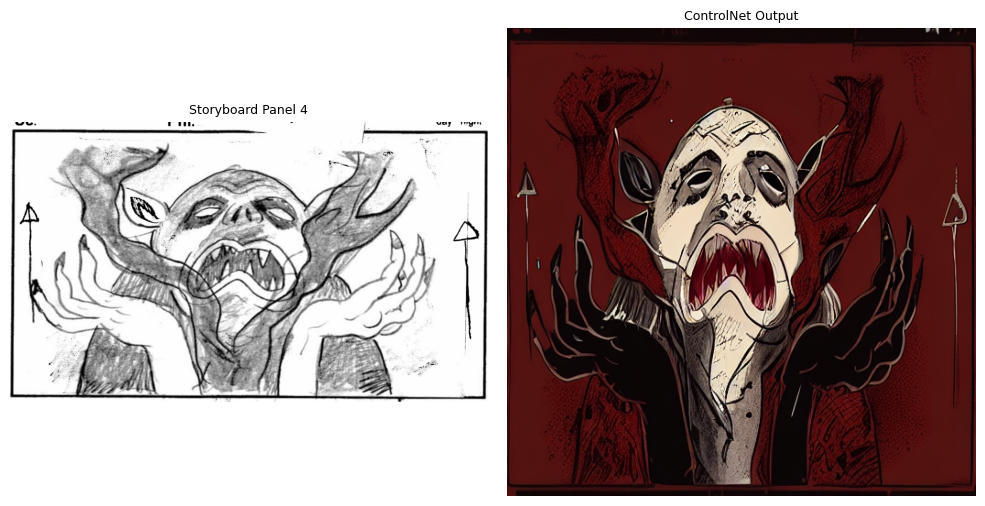

In [19]:
controlnet_test = run_sequence(
    pipe=controlnet_pipe,
    seq_name="test_seq",
    panel_files=[panel_files[3]],
    prompts=[prompts[3]],
    output_dir=OUTPUT_DIR,
    method="controlnet_test",
    cfg=SD15_CONFIG,
)

print("✓ ControlNet test completed")

show(
    [
        load_rgb(panel_files[3]),
        controlnet_test[0],
    ],
    titles=[
        "Storyboard Panel 4",
        "ControlNet Output",
    ],
    cols=2,
    size=5,
)

## Run the full ControlNet sequence

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


✓ Generated 6 ControlNet panels


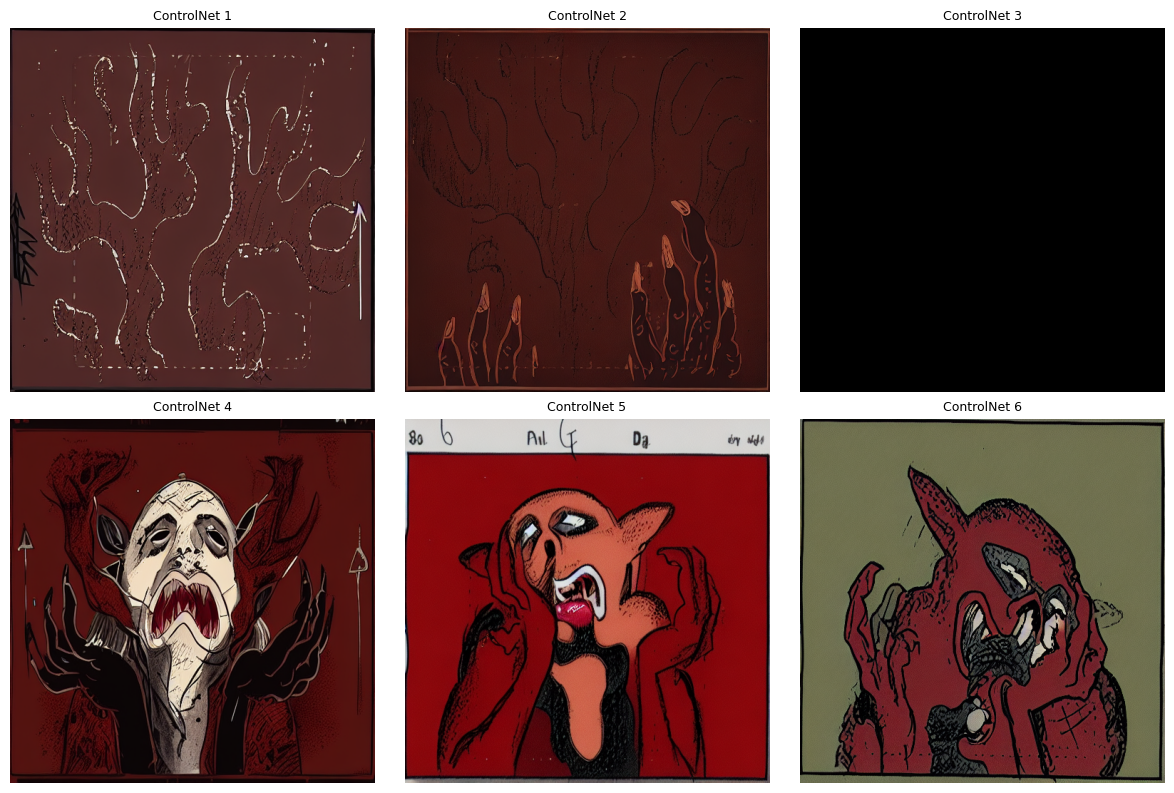

In [20]:
controlnet_frames = run_sequence(
    pipe=controlnet_pipe,
    seq_name=SEQ_NAME,
    panel_files=panel_files,
    prompts=prompts,
    output_dir=OUTPUT_DIR,
    method="controlnet_baseline",
    cfg=SD15_CONFIG,
)

print(
    f"✓ Generated {len(controlnet_frames)} "
    "ControlNet panels"
)

show(
    controlnet_frames,
    titles=[
        f"ControlNet {i + 1}"
        for i in range(len(controlnet_frames))
    ],
    cols=3,
    size=4,
)

## Find the saved character reference

In [21]:
character_ref_files = sorted(
    list(REF_DIR.glob("*.png"))
    + list(REF_DIR.glob("*.jpg"))
    + list(REF_DIR.glob("*.jpeg"))
)

print(
    "Character reference files:",
    len(character_ref_files),
)

for i, path in enumerate(character_ref_files):
    print(
        i,
        path.name,
    )

Character reference files: 1
0 vampire_ref.png


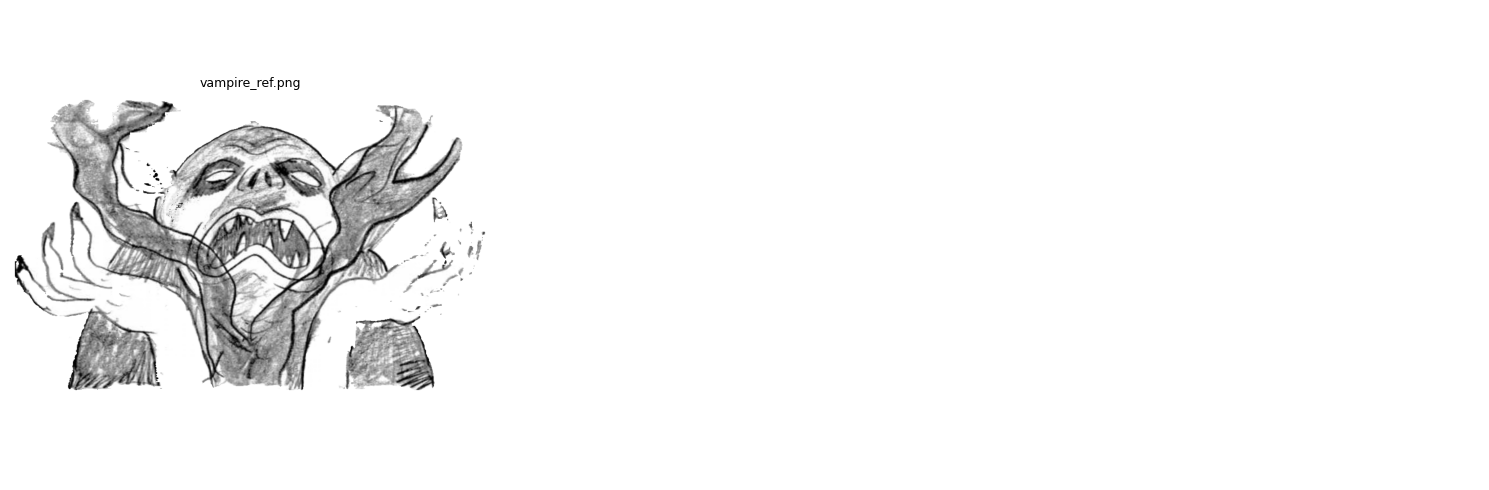

In [22]:
character_references = [
    load_rgb(char_ref)
    for char_ref in character_ref_files
]

show(
    character_references,
    titles=[
        Path(char_ref).name
        for char_ref in character_ref_files
    ],
    cols=3,
    size=5,
)

## Attach IP-Adapter

In [23]:
controlnet_pipe = attach_ip_adapter(
    pipe=controlnet_pipe,
    ip_cfg=IP_ADAPTER_CONFIG,
)

print(
    "IP-Adapter loaded"
)

print(
    "IP-Adapter scale:",
    IP_ADAPTER_CONFIG["scale"],
)

ip-adapter-plus_sd15.bin:   0%|          | 0.00/158M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/560 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.53G [00:00<?, ?B/s]

IP-Adapter loaded
IP-Adapter scale: 0.2


## Choose which reference to use for this run

In [24]:
SELECTED_REF_INDEX = 0

CHARACTER_REF_PATH = character_ref_files[
    SELECTED_REF_INDEX
]

character_reference = character_references[
    SELECTED_REF_INDEX
]

print(
    "Using character reference:",
    CHARACTER_REF_PATH.name,
)

Using character reference: vampire_ref.png


## Full IP-Adapter sequence

In [25]:
ip_adapter_frames = run_sequence_ip_adapter(
    pipe=controlnet_pipe,
    seq_name=SEQ_NAME,
    panel_files=panel_files,
    prompts=prompts,
    character_reference=character_reference,
    output_dir=OUTPUT_DIR,
    method="controlnet_ip_adapter",
    cfg=SD15_CONFIG,
    ip_cfg=IP_ADAPTER_CONFIG,
    reference_path=CHARACTER_REF_PATH,
)

print(
    "Generated",
    len(ip_adapter_frames),
    "IP-Adapter panels",
)

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Generated 6 IP-Adapter panels


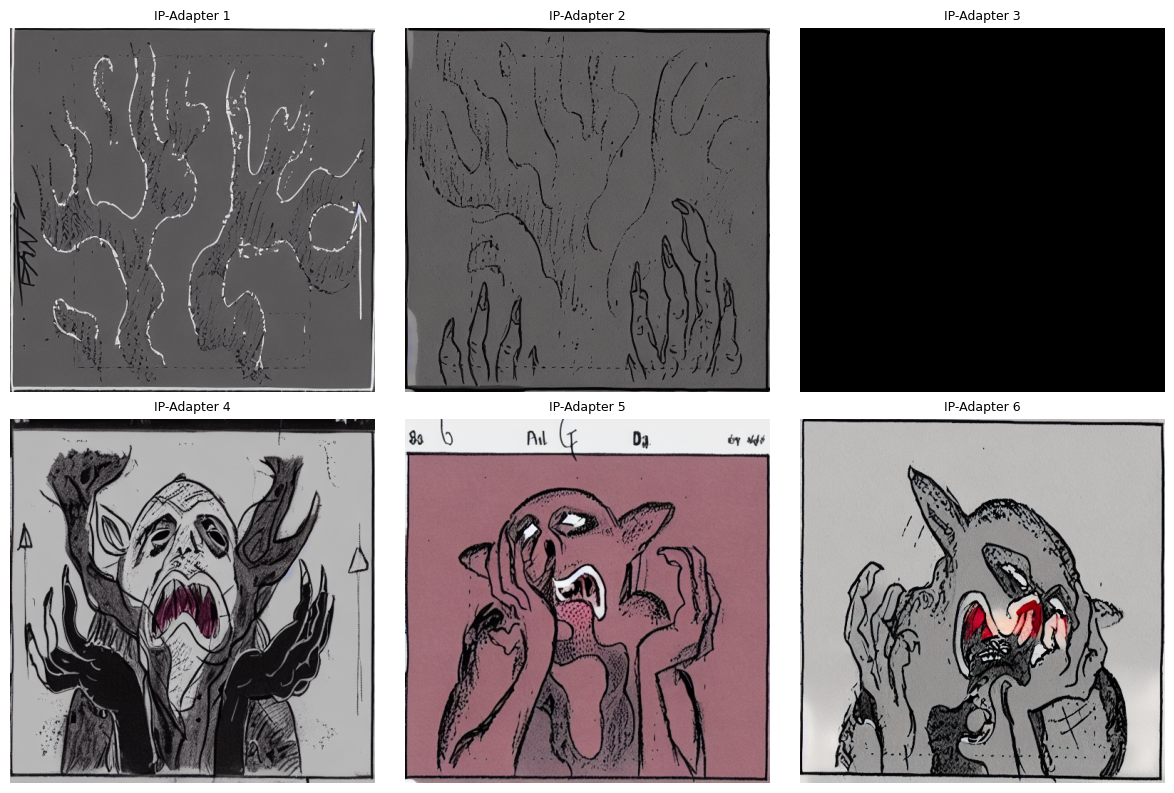

In [26]:
show(
    ip_adapter_frames,
    titles=[
        f"IP-Adapter {i + 1}"
        for i in range(
            len(ip_adapter_frames)
        )
    ],
    cols=3,
    size=4,
)

## Free SD1.5 pipeline before ConsiStory

helps free VRAM before loading ConsiStory.

In [27]:
import gc
import torch

del controlnet_pipe
gc.collect()
torch.cuda.empty_cache()

print(
    "Released SD1.5 ControlNet and IP-Adapter pipeline from memory"
)

Released SD1.5 ControlNet and IP-Adapter pipeline from memory


## Install ConsiStory attention fallback

In [28]:
install_torch_sdpa_fallback()

print(
    "Installed PyTorch attention fallback for ConsiStory"
)

Installed PyTorch attention fallback for ConsiStory


## Load ConsiStory pipeline

In [29]:
story_pipeline = load_consistory_pipeline(
    gpu_id=0,
)

print(
    "ConsiStory pipeline loaded"
)

config.json: 0.00B [00:00, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/10.3G [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/479 [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/737 [00:00<?, ?B/s]

... (10 outputs left out)

diffusion_pytorch_model.fp16.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

diffusion_pytorch_model.fp16.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

ConsiStory pipeline loaded


### Load and attach SDXL ControlNet to ConsiStory

In [30]:
consistory_controlnet = load_consistory_controlnet(
    model_name=CONSISTORY_CONFIG["controlnet"],
    device="cuda",
)

story_pipeline = attach_controlnet(
    story_pipeline=story_pipeline,
    controlnet=consistory_controlnet,
    conditioning_scale=CONSISTORY_CONFIG[
        "controlnet_conditioning_scale"
    ],
)

control_image_processor = make_control_image_processor(
    story_pipeline
)

print(
    "Attached SDXL ControlNet to ConsiStory pipeline"
)

config.json: 0.00B [00:00, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

Attached SDXL ControlNet to ConsiStory pipeline


### Switch ConsiStory to DPM-Solver++

In [31]:
dpm_dift_timestep = configure_dpm_solver_pp(
    story_pipeline=story_pipeline,
    n_steps=CONSISTORY_CONFIG["steps"],
    original_dift_timestep=261,
)

print(
    "ConsiStory DPM-Solver++ steps:",
    CONSISTORY_CONFIG["steps"],
)

print(
    "Chosen DIFT timestep:",
    dpm_dift_timestep,
)

ConsiStory DPM-Solver++ steps: 20
Chosen DIFT timestep: 283


## Generate ConsiStory anchor caches

In [32]:
(
    anchor_images,
    anchor_grid,
    dpm_anchor_cache_first_stage,
    dpm_anchor_cache_second_stage,
) = generate_anchor_caches(
    story_pipeline=story_pipeline,
    anchor_prompts=ANCHOR_PROMPTS,
    concept_token=CONCEPT_TOKEN,
    cfg=CONSISTORY_CONFIG,
    n_steps=CONSISTORY_CONFIG["steps"],
    cache_cpu_offloading=True,
)

print(
    "Generated ConsiStory anchor caches"
)

[(1, 20)]


  0%|          | 0/20 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/torch_utils.py:106: UserWarning: ComplexHalf support is experimental and many operators don't support it yet. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/EmptyTensor.cpp:54.)
  x_freq = fftn(x, dim=(-2, -1))


  0%|          | 0/20 [00:00<?, ?it/s]

Generated ConsiStory anchor caches


### Full ConsiStory sequence

In [33]:
consistory_frames = run_sequence_consistory(
    story_pipeline=story_pipeline,
    control_image_processor=control_image_processor,
    seq_name=SEQ_NAME,
    panel_files=panel_files,
    prompts=prompts,
    anchor_cache_first_stage=dpm_anchor_cache_first_stage,
    anchor_cache_second_stage=dpm_anchor_cache_second_stage,
    output_dir=OUTPUT_DIR,
    concept_token=CONCEPT_TOKEN,
    anchor_prompts=ANCHOR_PROMPTS,
    method="controlnet_consistory_dpmpp20",
    cfg=CONSISTORY_CONFIG,
    n_steps=CONSISTORY_CONFIG["steps"],
)

print(
    "Generated",
    len(consistory_frames),
    "ConsiStory panels",
)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

Generated 6 ConsiStory panels


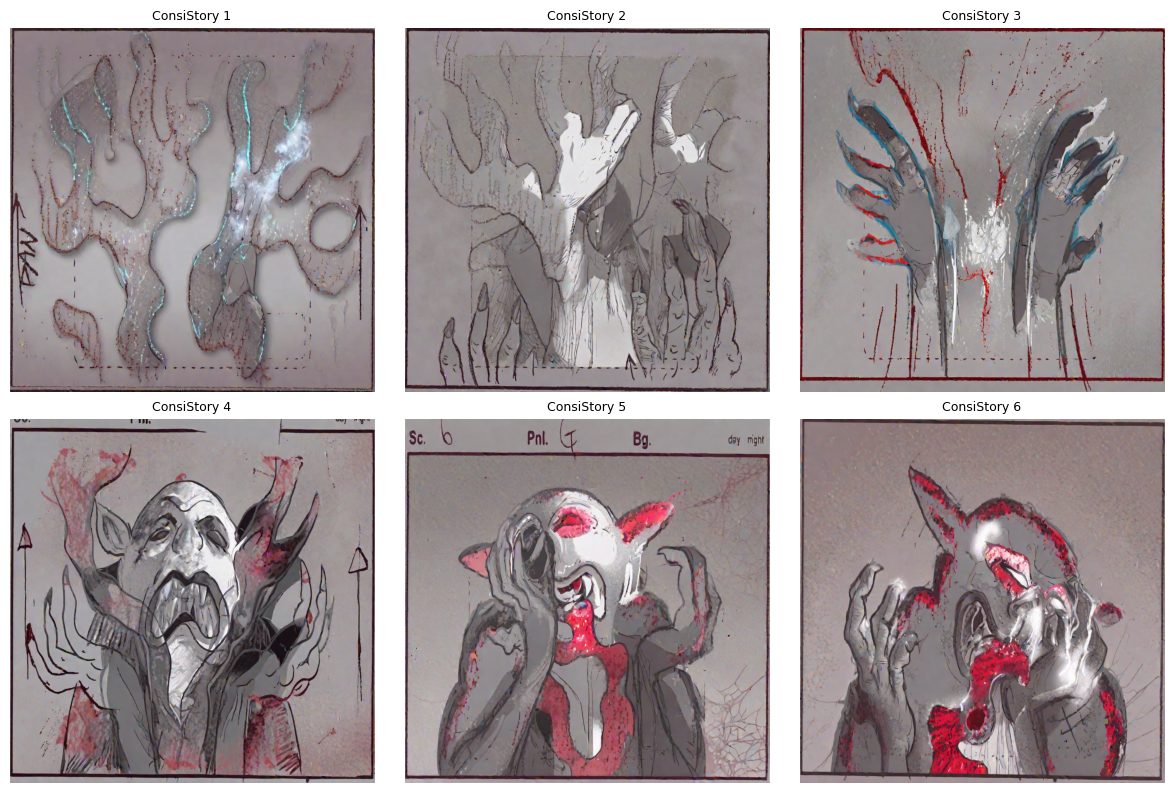

In [34]:
show(
    consistory_frames,
    titles=[
        f"ConsiStory {i + 1}"
        for i in range(
            len(consistory_frames)
        )
    ],
    cols=3,
    size=4,
)

### Method controls

In [35]:
RUN_CONTROLNET = True
RUN_IP_ADAPTER = True
RUN_CONSISTORY = True

# Rishi's implementation will be added later.
RUN_STORYDIFFUSION = False

## Benchmark sequence definitions

In [36]:
# SEQUENCES = {
#     "seq01": {
#         "character": "a vampire",

#         "setting": "blank background",

#         "actions": [
#             "jelly vaporizes as camera pans up",
#             "vampire hands slowly come into screen, close-up",
#             "hands rapidly push vaporized blood upwards, close-up",
#             "camera pans upto vampire's face, close-up",
#             "vampire inhales jelly mist from right hand, close-up",
#             "vampire inhales jelly mist from left hand, close-up",
#         ],

#         "character_reference_index": 0,
#     },
# }

SEQUENCES = {
    "seq01": {

        "character":
            "a vampire",

        "setting":
            "blank background",

        "actions": [
            "jelly vaporizes as camera pans up",
            "vampire hands slowly come into screen, close-up",
            "hands rapidly push vaporized blood upwards, close-up",
            "camera pans upto vampire's face, close-up",
            "vampire inhales jelly mist from right hand, close-up",
            "vampire inhales jelly mist from left hand, close-up",
        ],

        "character_reference_index":
            0,

        "concept_token": [
            "vampire"
        ],

        "anchor_prompts": [
            (
                "a western animation vampire, "
                "front-facing portrait, "
                "clean character design"
            ),
            (
                "a western animation vampire, "
                "three-quarter view portrait, "
                "clean character design"
            ),
        ],
    },
}

## Prepare all benchmark sequences

In [37]:
import glob

benchmark_sequences = {}

for seq_name, sequence_info in SEQUENCES.items():

    panel_files = sorted(
        glob.glob(
            str(
                PANEL_DIR
                / f"{seq_name}_panel*.png"
            )
        )
    )

    prompts = [
        (
            f"{sequence_info['character']}, "
            f"{action}, "
            f"{sequence_info['setting']}"
        )
        for action in sequence_info["actions"]
    ]

    prompts = prompts[:len(panel_files)]

    reference_index = sequence_info[
        "character_reference_index"
    ]

    character_reference = character_references[
        reference_index
    ]

    character_reference_path = character_ref_files[
        reference_index
    ]

    benchmark_sequences[seq_name] = {
        "panel_files": panel_files,
        "prompts": prompts,
        "character_reference": character_reference,
        "character_reference_path": (
            character_reference_path
        ),
    }


for seq_name, data in benchmark_sequences.items():

    print()
    print("Sequence:", seq_name)
    print("Panels:", len(data["panel_files"]))
    print(
        "Character reference:",
        data["character_reference_path"].name,
    )


Sequence: seq01
Panels: 6
Character reference: vampire_ref.png


## ControlNet benchmark section

In [38]:
if RUN_CONTROLNET or RUN_IP_ADAPTER:

    controlnet_pipe = load_controlnet_pipeline(
        cfg=SD15_CONFIG,
        device="cuda",
    )

    print(
        "SD1.5 ControlNet pipeline loaded"
    )

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

SD1.5 ControlNet pipeline loaded


In [39]:
controlnet_results = {}

if RUN_CONTROLNET:

    for seq_name, data in benchmark_sequences.items():

        print()
        print("Running ControlNet:", seq_name)

        frames = run_sequence(
            pipe=controlnet_pipe,
            seq_name=seq_name,
            panel_files=data["panel_files"],
            prompts=data["prompts"],
            output_dir=OUTPUT_DIR,
            method="controlnet_baseline",
            cfg=SD15_CONFIG,
        )

        controlnet_results[
            seq_name
        ] = frames


Running ControlNet: seq01


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


In [40]:
if RUN_IP_ADAPTER:

    controlnet_pipe = attach_ip_adapter(
        pipe=controlnet_pipe,
        ip_cfg=IP_ADAPTER_CONFIG,
    )

    print(
        "IP-Adapter loaded"
    )

    print(
        "IP-Adapter scale:",
        IP_ADAPTER_CONFIG["scale"],
    )

IP-Adapter loaded
IP-Adapter scale: 0.2


# IP-Adapter loop

In [41]:
ip_adapter_results = {}

if RUN_IP_ADAPTER:

    for seq_name, data in benchmark_sequences.items():

        print()
        print(
            "Running IP-Adapter:",
            seq_name,
        )

        print(
            "Reference:",
            data[
                "character_reference_path"
            ].name,
        )

        frames = run_sequence_ip_adapter(
            pipe=controlnet_pipe,
            seq_name=seq_name,
            panel_files=data["panel_files"],
            prompts=data["prompts"],
            character_reference=data[
                "character_reference"
            ],
            output_dir=OUTPUT_DIR,
            method="controlnet_ip_adapter",
            cfg=SD15_CONFIG,
            ip_cfg=IP_ADAPTER_CONFIG,
            reference_path=data[
                "character_reference_path"
            ],
        )

        ip_adapter_results[
            seq_name
        ] = frames


Running IP-Adapter: seq01
Reference: vampire_ref.png


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


#### free the SD1.5 pipeline

In [42]:
import gc
import torch

if "controlnet_pipe" in globals():
    del controlnet_pipe

gc.collect()
torch.cuda.empty_cache()

print(
    "Released SD1.5 models from GPU memory"
)

Released SD1.5 models from GPU memory


# ConsiStory

Install ConsiStory attention fallback

In [43]:
if RUN_CONSISTORY:

    install_torch_sdpa_fallback()

    print(
        "ConsiStory attention fallback loaded"
    )

ConsiStory attention fallback loaded


### Load ConsiStory

In [44]:
if RUN_CONSISTORY:

    story_pipeline = load_consistory_pipeline(
        gpu_id=0,
    )

    print(
        "ConsiStory pipeline loaded"
    )

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

ConsiStory pipeline loaded


### Load SDXL ControlNet

In [45]:
if RUN_CONSISTORY:

    consistory_controlnet = (
        load_consistory_controlnet(
            model_name=(
                CONSISTORY_CONFIG[
                    "controlnet"
                ]
            ),
            device="cuda",
        )
    )

    print(
        "SDXL ControlNet loaded"
    )

SDXL ControlNet loaded


### Attach ControlNet to ConsiStory

In [46]:
if RUN_CONSISTORY:

    story_pipeline = attach_controlnet(
        story_pipeline=story_pipeline,
        controlnet=consistory_controlnet,
        conditioning_scale=(
            CONSISTORY_CONFIG[
                "controlnet_conditioning_scale"
            ]
        ),
    )

    control_image_processor = (
        make_control_image_processor(
            story_pipeline
        )
    )

    print(
        "ControlNet attached to ConsiStory"
    )

ControlNet attached to ConsiStory


#### Configure DPM-Solver++

In [47]:
if RUN_CONSISTORY:

    dpm_dift_timestep = (
        configure_dpm_solver_pp(
            story_pipeline=story_pipeline,
            n_steps=(
                CONSISTORY_CONFIG[
                    "steps"
                ]
            ),
            original_dift_timestep=261,
        )
    )

    print(
        "DPM-Solver++ steps:",
        CONSISTORY_CONFIG[
            "steps"
        ],
    )

    print(
        "DIFT timestep:",
        dpm_dift_timestep,
    )

DPM-Solver++ steps: 20
DIFT timestep: 283


### Run ConsiStory benchmark

In [48]:
consistory_results = {}

if RUN_CONSISTORY:

    for seq_name, data in benchmark_sequences.items():

        sequence_info = SEQUENCES[
            seq_name
        ]

        print()
        print(
            "Preparing ConsiStory:",
            seq_name,
        )

        (
            anchor_images,
            anchor_grid,
            anchor_cache_first_stage,
            anchor_cache_second_stage,
        ) = generate_anchor_caches(
            story_pipeline=story_pipeline,
            anchor_prompts=(
                sequence_info[
                    "anchor_prompts"
                ]
            ),
            concept_token=(
                sequence_info[
                    "concept_token"
                ]
            ),
            cfg=CONSISTORY_CONFIG,
            n_steps=(
                CONSISTORY_CONFIG[
                    "steps"
                ]
            ),
            cache_cpu_offloading=True,
        )

        print(
            "Generating ConsiStory:",
            seq_name,
        )

        frames = run_sequence_consistory(
            story_pipeline=story_pipeline,
            control_image_processor=(
                control_image_processor
            ),
            seq_name=seq_name,
            panel_files=data[
                "panel_files"
            ],
            prompts=data[
                "prompts"
            ],
            anchor_cache_first_stage=(
                anchor_cache_first_stage
            ),
            anchor_cache_second_stage=(
                anchor_cache_second_stage
            ),
            output_dir=OUTPUT_DIR,
            concept_token=(
                sequence_info[
                    "concept_token"
                ]
            ),
            anchor_prompts=(
                sequence_info[
                    "anchor_prompts"
                ]
            ),
            method=(
                "controlnet_consistory_dpmpp20"
            ),
            cfg=CONSISTORY_CONFIG,
            n_steps=(
                CONSISTORY_CONFIG[
                    "steps"
                ]
            ),
        )

        consistory_results[
            seq_name
        ] = frames

        print(
            "Generated",
            len(frames),
            "ConsiStory panels",
        )

        del anchor_cache_first_stage
        del anchor_cache_second_stage
        del anchor_images
        del anchor_grid

        gc.collect()
        torch.cuda.empty_cache()


Preparing ConsiStory: seq01
[(1, 20)]


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

Generating ConsiStory: seq01


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

Generated 6 ConsiStory panels


### Release ConsiStory models

In [49]:
if "story_pipeline" in globals():
    del story_pipeline

if "consistory_controlnet" in globals():
    del consistory_controlnet

if "control_image_processor" in globals():
    del control_image_processor

gc.collect()
torch.cuda.empty_cache()

print(
    "Released ConsiStory models from GPU memory"
)

Released ConsiStory models from GPU memory


# StoryDiffusion section

In [50]:
from src.storydiffusion_csa import (
    install_csa,
    run_sequence_batch,
)

In [51]:
RUN_STORYDIFFUSION = True

CSA_CONFIG = {
    "rate": 0.5,
    "max_tokens": 1024,
}

### Load SD1.5 ControlNet and install CSA

In [52]:
if RUN_STORYDIFFUSION:

    storydiffusion_pipe = load_controlnet_pipeline(
        cfg=SD15_CONFIG,
        device="cuda",
    )

    processor_count = install_csa(
        storydiffusion_pipe
    )

    print(
        "StoryDiffusion CSA processors installed:",
        processor_count,
    )

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

StoryDiffusion CSA processors installed: 16


## Run StoryDiffusion benchmark

Unlike the ControlNet and IP-Adapter runners, this generates the entire sequence as a batch, allowing the panels to share information through self-attention.

The memory needed depends on the number of panels in each batch.

In [53]:
storydiffusion_results = {}

if RUN_STORYDIFFUSION:

    for seq_name, data in benchmark_sequences.items():

        print()
        print(
            "Running StoryDiffusion CSA:",
            seq_name,
        )

        frames = run_sequence_batch(
            pipe=storydiffusion_pipe,
            seq_name=seq_name,
            panel_files=data["panel_files"],
            prompts=data["prompts"],
            output_dir=OUTPUT_DIR,
            method="controlnet_storydiffusion_csa",
            use_csa=True,
            cfg=SD15_CONFIG,
            rate=CSA_CONFIG["rate"],
            max_tokens=CSA_CONFIG["max_tokens"],
        )

        storydiffusion_results[seq_name] = frames

        print(
            "Generated",
            len(frames),
            "StoryDiffusion panels",
        )


Running StoryDiffusion CSA: seq01


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Generated 6 StoryDiffusion panels


#### Release StoryDiffusion models

In [54]:
if "storydiffusion_pipe" in globals():
    del storydiffusion_pipe

gc.collect()
torch.cuda.empty_cache()

print(
    "Released StoryDiffusion models from GPU memory"
)

Released StoryDiffusion models from GPU memory


### Visualize StoryDiffusion outputs

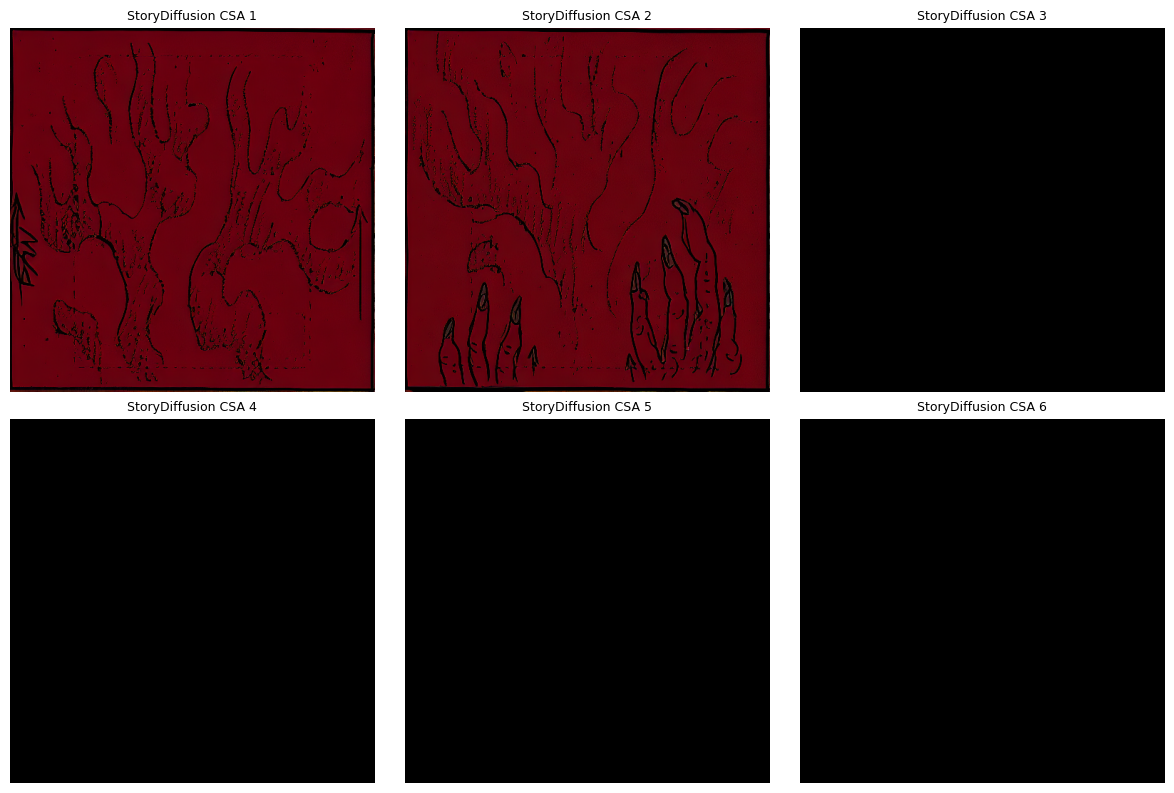

In [55]:
for seq_name, frames in storydiffusion_results.items():

    show(
        frames,
        titles=[
            f"StoryDiffusion CSA {i + 1}"
            for i in range(len(frames))
        ],
        cols=3,
        size=4,
    )

## Final benchmark summary

In [56]:
from pathlib import Path

METHOD_DIRS = {
    "ControlNet": "controlnet_baseline",
    "IP-Adapter": "controlnet_ip_adapter",
    "ConsiStory": "controlnet_consistory_dpmpp20",
    "StoryDiffusion CSA": "controlnet_storydiffusion_csa",
}

if RUN_STORYDIFFUSION:
    METHOD_DIRS[
        "StoryDiffusion"
    ] = "controlnet_storydiffusion"


print()
print("Benchmark generation summary")
print()

for seq_name, data in benchmark_sequences.items():

    input_count = len(
        data["panel_files"]
    )

    print(
        seq_name,
        ":",
        input_count,
        "input panels",
    )

    for method_name, method_dir in METHOD_DIRS.items():

        result_dir = (
            OUTPUT_DIR
            / method_dir
            / seq_name
        )

        generated_files = sorted(
            result_dir.glob(
                "panel[0-9][0-9].png"
            )
        )

        print(
            f"  {method_name}:",
            len(generated_files),
        )

    print()


Benchmark generation summary

seq01 : 6 input panels
  ControlNet: 6
  IP-Adapter: 6
  ConsiStory: 6
  StoryDiffusion CSA: 6
  StoryDiffusion: 0



### Save benchmark information

In [57]:
import json
import time

benchmark_manifest = {
    "created_at":
        time.strftime(
            "%Y-%m-%d %H:%M:%S"
        ),

    "methods": {
        "controlnet":
            RUN_CONTROLNET,

        "ip_adapter":
            RUN_IP_ADAPTER,

        "consistory":
            RUN_CONSISTORY,

        "storydiffusion":
            RUN_STORYDIFFUSION,
    },

    "sequences": {},
}


for seq_name, data in benchmark_sequences.items():

    sequence_info = SEQUENCES[
        seq_name
    ]

    benchmark_manifest[
        "sequences"
    ][seq_name] = {

        "panel_count":
            len(
                data[
                    "panel_files"
                ]
            ),

        "panel_files": [
            str(path)
            for path in data[
                "panel_files"
            ]
        ],

        "prompts":
            data[
                "prompts"
            ],

        "character_reference":
            str(
                data[
                    "character_reference_path"
                ]
            ),

        "concept_token":
            sequence_info.get(
                "concept_token"
            ),

        "anchor_prompts":
            sequence_info.get(
                "anchor_prompts"
            ),
    }


manifest_path = (
    OUTPUT_DIR
    / "benchmark_manifest.json"
)

with open(
    manifest_path,
    "w",
) as file:

    json.dump(
        benchmark_manifest,
        file,
        indent=2,
    )


print(
    "Saved benchmark manifest:"
)

print(
    manifest_path
)

Saved benchmark manifest:
/content/drive/MyDrive/cmpe261_project/outputs/benchmark_manifest.json
